In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
final = pd.read_csv("drivers_clean.csv",
                    parse_dates=["interview_date_clean", "onboarding_date_clean"])
print(final.shape)

(48568, 46)


In [3]:
from scipy.stats import chi2_contingency, kruskal

rows = []

In [4]:
# pass  rate vs kota, platform, jenis kendaraan
d = final[final["interview_result"].notna()]
for seg in ["city", "platform", "vehicle_type"]:
    ct = pd.crosstab(d[seg], d["interview_result"].eq("Selected"))
    chi2, p, dof, _ = chi2_contingency(ct)
    rows.append((f"pass rate vs {seg}", "chi-square", round(chi2, 2), dof, round(p, 3)))

In [5]:
# active rate vs kota
ct = pd.crosstab(final["city"], final["is_active_clean"])
chi2, p, dof, _ = chi2_contingency(ct)
rows.append(("active rate vs city", "chi-square", round(chi2, 2), dof, round(p, 3)))

In [6]:
# earnings, trips, rating vs platform
for col in ["earn_clean", "trips_clean", "rating_clean"]:
    groups = [g[col].dropna() for _, g in final.groupby("platform")]
    stat, p = kruskal(*groups)
    rows.append((f"{col} vs platform", "Kruskal-Wallis", round(stat, 2), len (groups) - 1, round(p, 3)))

In [7]:
hasil = pd.DataFrame(rows, columns=["perbandingan", "uji", "statistik", "dof", "p_value"])
hasil["signifikan"] = hasil["p_value"] < 0.05 / len(hasil)
print(hasil.to_string(index=False))

             perbandingan            uji  statistik  dof  p_value  signifikan
        pass rate vs city     chi-square       4.48    9    0.877       False
    pass rate vs platform     chi-square       2.63    3    0.453       False
pass rate vs vehicle_type     chi-square       7.54    4    0.110       False
      active rate vs city     chi-square       5.97    9    0.743       False
   earn_clean vs platform Kruskal-Wallis       2.12    3    0.548       False
  trips_clean vs platform Kruskal-Wallis       1.90    3    0.593       False
 rating_clean vs platform Kruskal-Wallis       2.10    3    0.552       False


In [8]:
os.makedirs("docs", exist_ok=True)
hasil.to_csv("docs/hasil_uji_statistik.csv", index=False)

In [9]:
os.makedirs("docs/imh", exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
BIRU, MERAH = "#4C78A8", "#E45756"

def titik(v):
    return f"{v:,}".replace(",", ".")

In [10]:
import os
os.makedirs("docs/img", exist_ok=True)
print(os.getcwd())                   # seharusnya berakhir di ...project-1
print(os.path.exists("docs/img"))    # seharusnya True

c:\Github\project-1
True


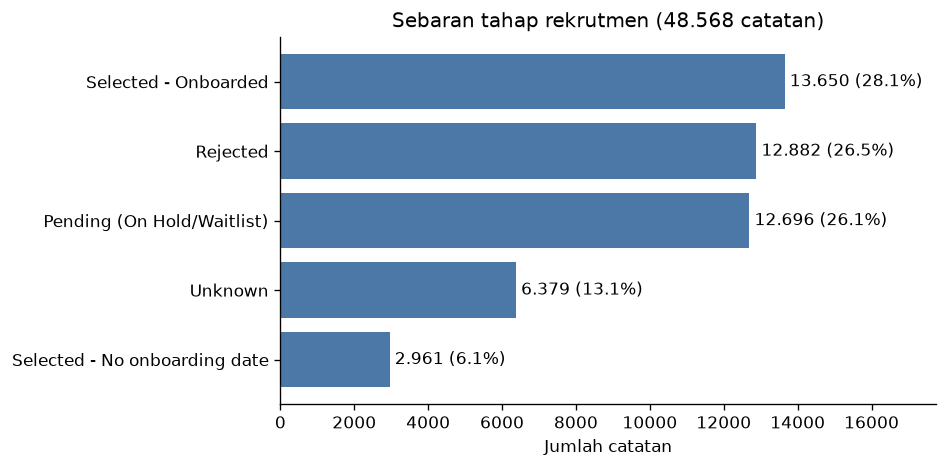

In [11]:
# Grafik 1: sebaran tahap rekrutmen
fs = final["funnel_stage"].value_counts()
pct = (fs / fs.sum() * 100).round(1)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(fs.index[::-1], fs.values[::-1], color=BIRU)
for b, v, p in zip(bars, fs.values[::-1], pct.values[::-1]):
    ax.text(b.get_width() + fs.max() * 0.01, b.get_y() + b.get_height() / 2,
            f"{titik(v)} ({p}%)", va="center")
ax.set_xlim(0, fs.max() * 1.3)
ax.set_title(f"Sebaran tahap rekrutmen ({titik(len(final))} catatan)")
ax.set_xlabel("Jumlah catatan")
plt.tight_layout()
plt.savefig("docs/img/01_funnel_stage.png")
plt.show()

In [12]:
# Fungsi grafik batang per kota
def bar_kota(series, overall, judul, ylabel, ymax, nama_file):
    series = series.sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(series.index, series.values, color=BIRU)
    ax.axhline(overall, color=MERAH, linestyle="--", label=f"Rata-rata keseluruhan {overall:.1f}%")
    for i, v in enumerate(series.values):
        ax.text(i, v + ymax * 0.01, f"{v:.1f}", ha="center")
    ax.set_ylim(0, ymax)
    ax.set_title(judul)
    ax.set_ylabel(ylabel)
    ax.legend(loc="upper right")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(nama_file)
    plt.show()

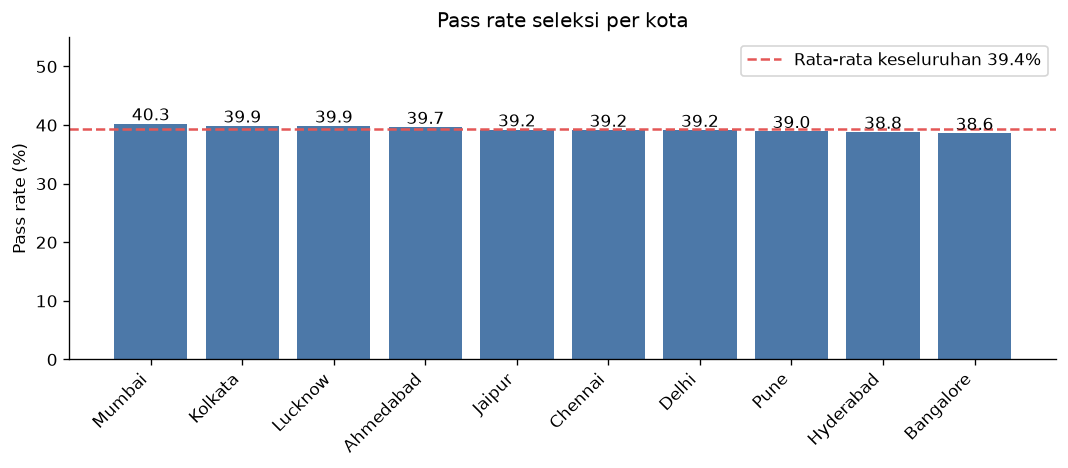

In [13]:
# Grafik 2: pass rate per kota
d = final[final["interview_result"].notna()].copy()
d["selected"] = d["interview_result"].eq("Selected")
pr = d.groupby("city")["selected"].mean() * 100
bar_kota(pr, d["selected"].mean() * 100, "Pass rate seleksi per kota",
         "Pass rate (%)", 55, "docs/img/02_pass_rate_kota.png")

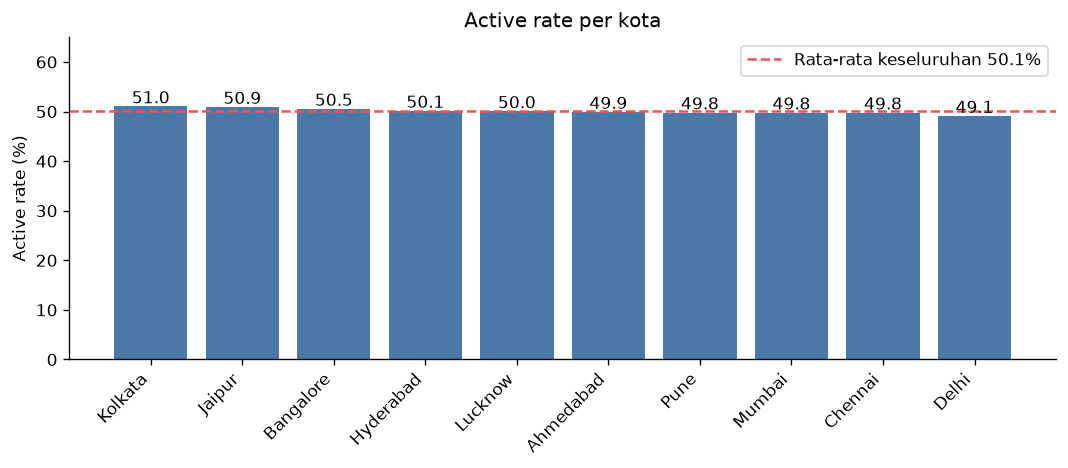

In [14]:
# Grafik 3: active rate per kota
ar = final.groupby("city")["is_active_clean"].mean() * 100
bar_kota(ar, final["is_active_clean"].mean() * 100, "Active rate per kota",
         "Active rate (%)", 65, "docs/img/03_active_rate_kota.png")

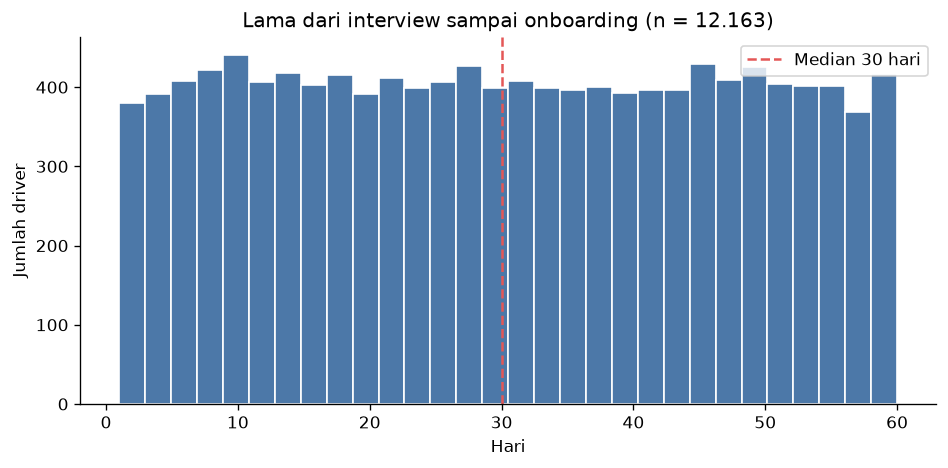

In [15]:
# Grafik 4: lama dari interview sampai onboarding
x = final["days_to_onboard"].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(x, bins=30, color=BIRU, edgecolor="white")
ax.axvline(x.median(), color=MERAH, linestyle="--", label=f"Median {x.median():.0f} hari")
ax.set_title(f"Lama dari interview sampai onboarding (n = {titik(len(x))})")
ax.set_xlabel("Hari")
ax.set_ylabel("Jumlah driver")
ax.legend()
plt.tight_layout()
plt.savefig("docs/img/04_days_to_onboard.png")
plt.show()

In [16]:
def cramers_v(ct):
    chi2 = chi2_contingency(ct)[0]
    return (chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1))) ** 0.5

d = final[final["interview_result"].notna()]
hasil_v = []
for seg in ["city", "platform", "vehicle_type"]:
    ct = pd.crosstab(d[seg], d["interview_result"].eq("Selected"))
    hasil_v.append((f"pass rate vs {seg}", round(cramers_v(ct), 3)))
ct = pd.crosstab(final["city"], final["is_active_clean"])
hasil_v.append(("active rate vs city", round(cramers_v(ct), 3)))

print(pd.DataFrame(hasil_v, columns=["perbandingan", "cramers_v"]).to_string(index=False))

             perbandingan  cramers_v
        pass rate vs city      0.010
    pass rate vs platform      0.008
pass rate vs vehicle_type      0.014
      active rate vs city      0.011


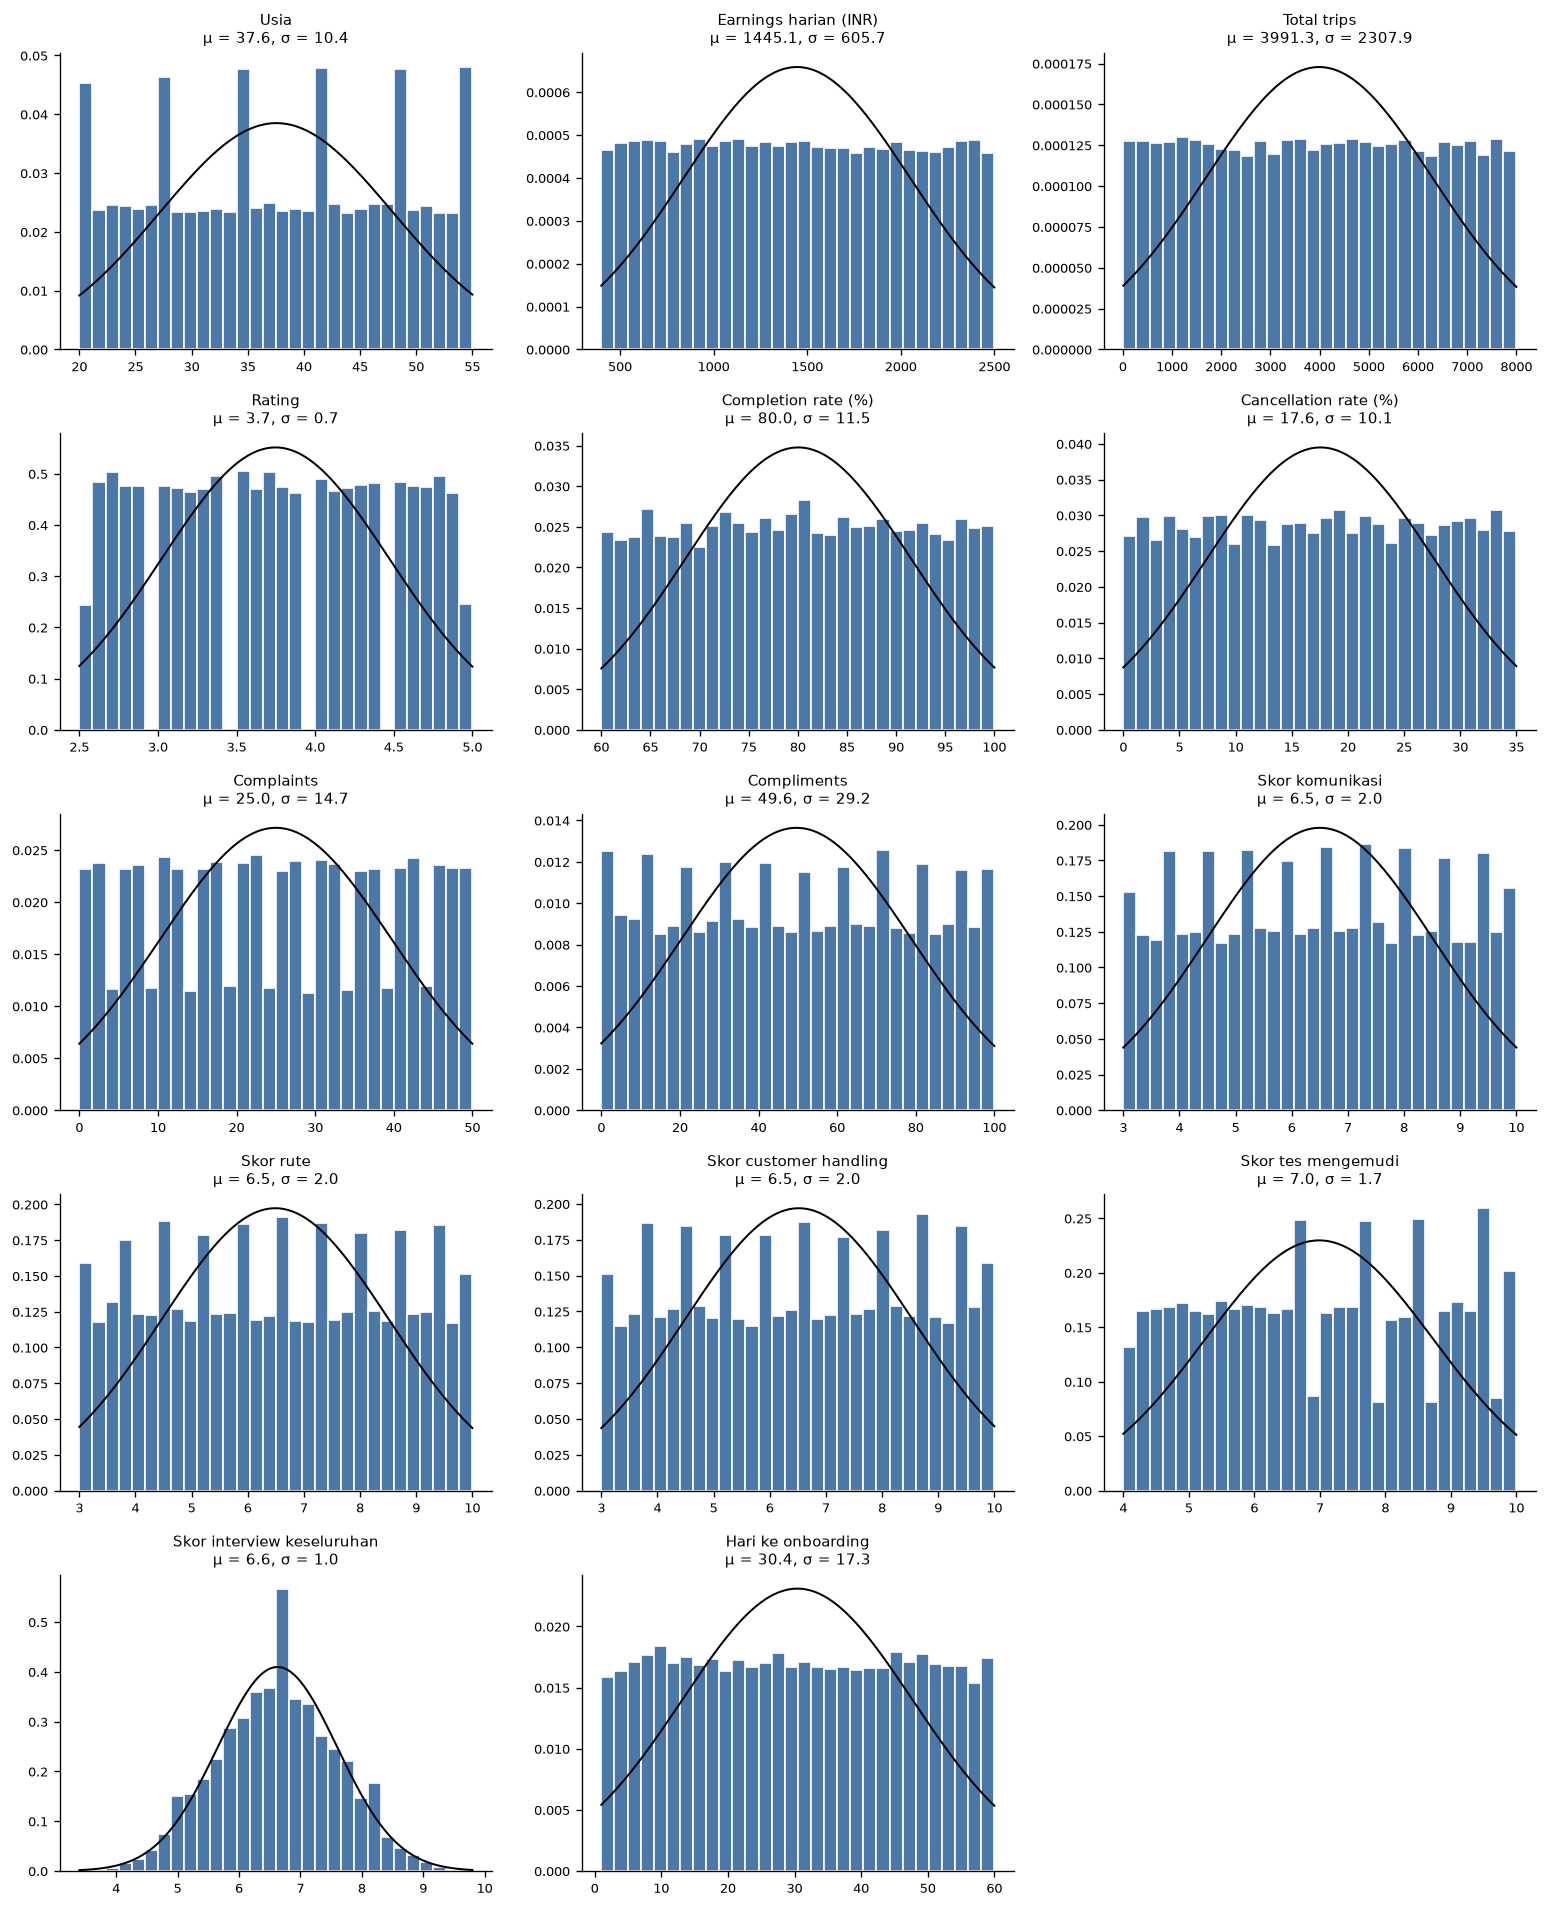

                     kolom     n  skew  kurtosis
                      Usia 43733 -0.01     -1.20
     Earnings harian (INR) 45636  0.01     -1.20
               Total trips 43130  0.00     -1.20
                    Rating 38846  0.00     -1.19
       Completion rate (%) 39376 -0.00     -1.18
     Cancellation rate (%) 39208 -0.00     -1.20
                Complaints 40714  0.00     -1.20
               Compliments 40727  0.01     -1.21
           Skor komunikasi 39343 -0.00     -1.19
                 Skor rute 39365  0.00     -1.20
    Skor customer handling 39346 -0.01     -1.21
        Skor tes mengemudi 39361  0.01     -1.20
Skor interview keseluruhan 39482 -0.00     -0.29
        Hari ke onboarding 12163  0.01     -1.21


In [17]:
import numpy as np
from scipy.stats import norm

num_cols = {
    "age_clean": "Usia", "earn_clean": "Earnings harian (INR)", "trips_clean": "Total trips",
    "rating_clean": "Rating", "trip_completion_rate_clean": "Completion rate (%)",
    "cancellation_rate_clean": "Cancellation rate (%)", "total_complaints_clean": "Complaints",
    "total_compliments_clean": "Compliments",
    "communication_score_10_clean": "Skor komunikasi", "route_knowledge_score_10_clean": "Skor rute",
    "customer_handling_score_10_clean": "Skor customer handling", "driving_test_score_10_clean": "Skor tes mengemudi",
    "overall_interview_score_10_clean": "Skor interview keseluruhan", "days_to_onboard": "Hari ke onboarding",
}

fig, axes = plt.subplots(5, 3, figsize=(13, 16))
for ax, (c, label) in zip(axes.ravel(), num_cols.items()):
    s = final[c].dropna().astype(float)
    ax.hist(s, bins=30, density=True, color="#4C78A8", edgecolor="white")
    xs = np.linspace(s.min(), s.max(), 200)
    ax.plot(xs, norm.pdf(xs, s.mean(), s.std()), color="black", linewidth=1.2)
    ax.set_title(f"{label}\nμ = {s.mean():.1f}, σ = {s.std():.1f}", fontsize=9)
    ax.tick_params(labelsize=8)
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("docs/img/05_distribusi_numerik.png")
plt.show()

ringkas = pd.DataFrame({
    "kolom": list(num_cols.values()),
    "n": [final[c].notna().sum() for c in num_cols],
    "skew": [final[c].skew() for c in num_cols],
    "kurtosis": [final[c].kurt() for c in num_cols],
}).round(2)
print(ringkas.to_string(index=False))

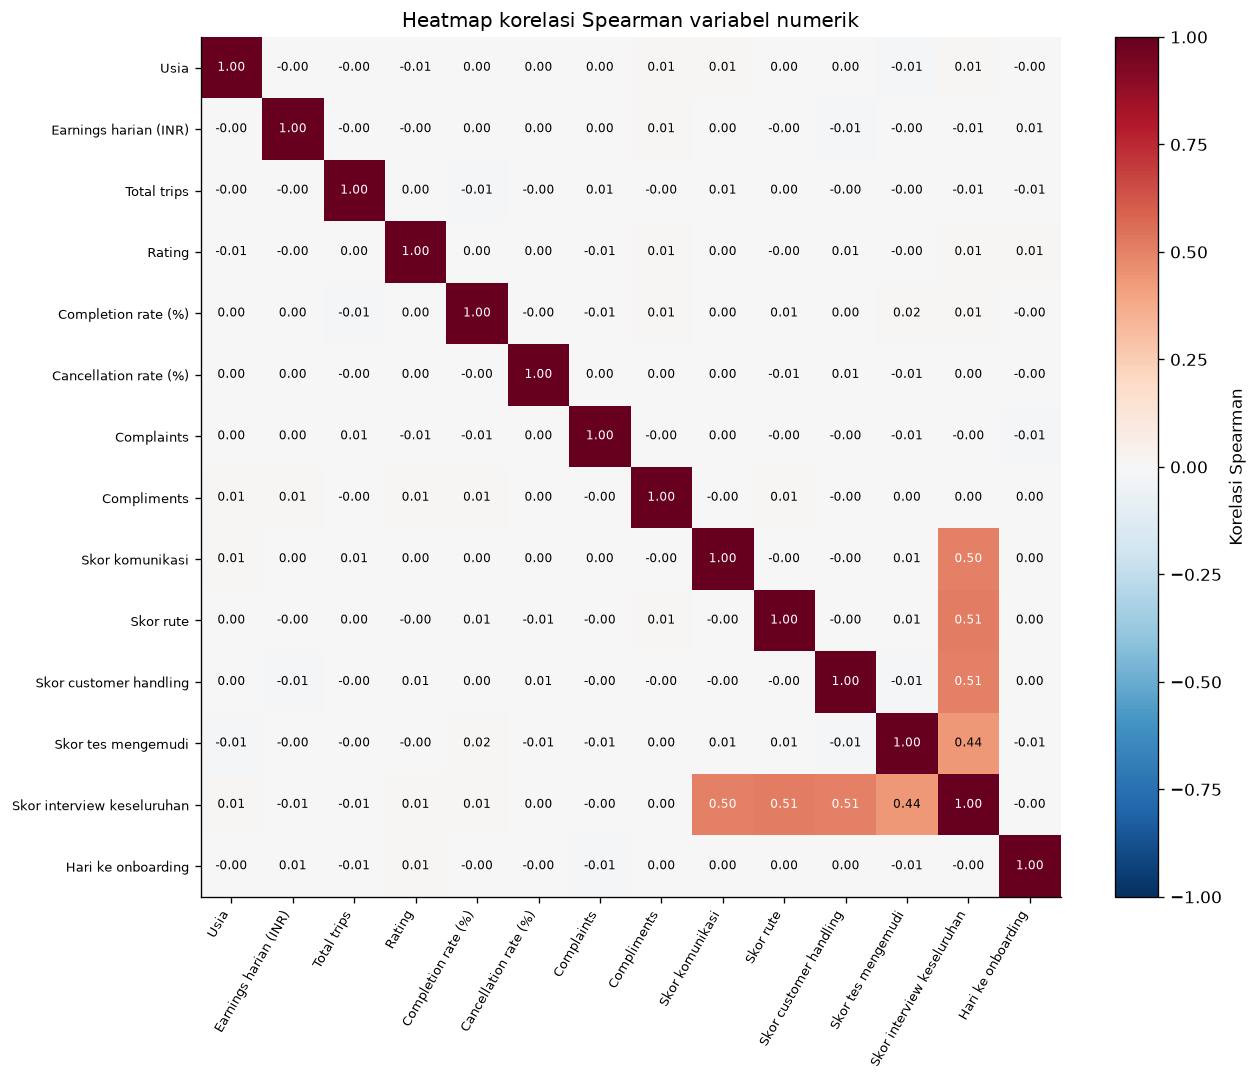

Skor rute               Skor interview keseluruhan    0.51
Skor customer handling  Skor interview keseluruhan    0.51
Skor komunikasi         Skor interview keseluruhan    0.50
Skor tes mengemudi      Skor interview keseluruhan    0.44
Completion rate (%)     Skor tes mengemudi            0.02
Complaints              Hari ke onboarding           -0.01
Total trips             Completion rate (%)          -0.01
Usia                    Skor komunikasi               0.01
dtype: float64


In [18]:
corr = final[list(num_cols)].corr(method="spearman")
corr.index = corr.columns = list(num_cols.values())

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.5 else "black")
fig.colorbar(im, ax=ax, label="Korelasi Spearman")
ax.set_title("Heatmap korelasi Spearman variabel numerik")
plt.tight_layout()
plt.savefig("docs/img/06_heatmap_korelasi.png")
plt.show()

pasangan = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pasangan.reindex(pasangan.abs().sort_values(ascending=False).index).head(8).round(2))

In [20]:
empat = ["communication_score_10_clean", "route_knowledge_score_10_clean",
         "customer_handling_score_10_clean", "driving_test_score_10_clean"]
lengkap = final[empat + ["overall_interview_score_10_clean"]].dropna()
selisih = (lengkap[empat].mean(axis=1) - lengkap["overall_interview_score_10_clean"]).abs()
print(len(lengkap), selisih.max().round(3))

16952 0.05


In [19]:
def cramers_v(ct):
    chi2 = chi2_contingency(ct)[0]
    return (chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1))) ** 0.5

d = final[final["interview_result"].notna()]
hasil_v = []
for seg in ["city", "platform", "vehicle_type"]:
    ct = pd.crosstab(d[seg], d["interview_result"].eq("Selected"))
    hasil_v.append((f"pass rate vs {seg}", round(cramers_v(ct), 3)))
ct = pd.crosstab(final["city"], final["is_active_clean"])
hasil_v.append(("active rate vs city", round(cramers_v(ct), 3)))

print(pd.DataFrame(hasil_v, columns=["perbandingan", "cramers_v"]).to_string(index=False))

             perbandingan  cramers_v
        pass rate vs city      0.010
    pass rate vs platform      0.008
pass rate vs vehicle_type      0.014
      active rate vs city      0.011


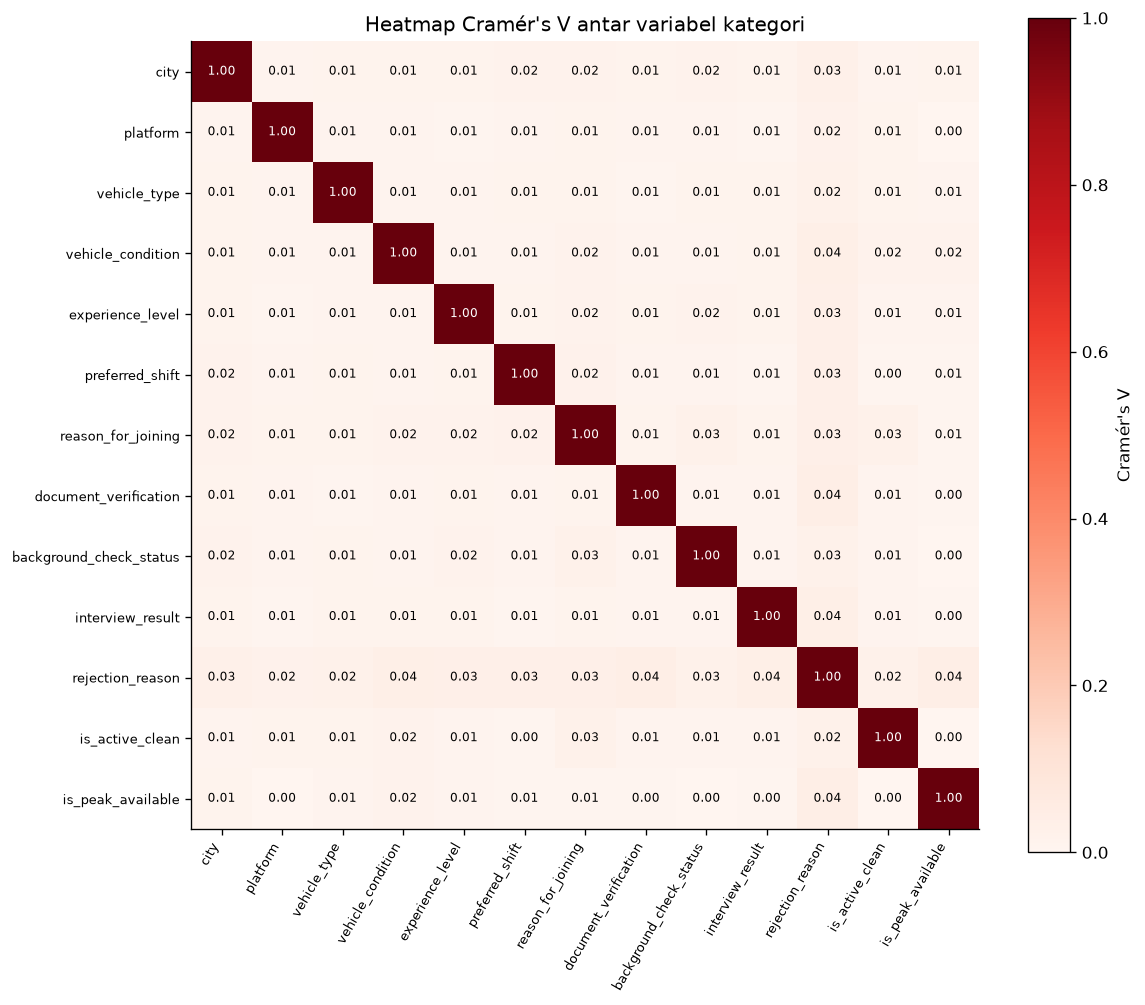

document_verification  rejection_reason     0.041
rejection_reason       is_peak_available    0.040
vehicle_condition      rejection_reason     0.039
interview_result       rejection_reason     0.038
reason_for_joining     rejection_reason     0.033
preferred_shift        rejection_reason     0.033
experience_level       rejection_reason     0.033
city                   rejection_reason     0.030
dtype: float64


In [24]:
cat_cols = ["city", "platform", "vehicle_type", "vehicle_condition", "experience_level",
            "preferred_shift", "reason_for_joining", "document_verification",
            "background_check_status", "interview_result", "rejection_reason",
            "is_active_clean", "is_peak_available"]

def cramers_v_pair(a, b):
    ct = pd.crosstab(final[a], final[b])
    if min(ct.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(ct)[0]
    return (chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1))) ** 0.5

V = pd.DataFrame(1.0, index=cat_cols, columns=cat_cols)
for i, a in enumerate(cat_cols):
    for b in cat_cols[i + 1:]:
        V.loc[a, b] = V.loc[b, a] = cramers_v_pair(a, b)

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(V.values, cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(len(V)))
ax.set_xticklabels(V.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(V)))
ax.set_yticklabels(V.index, fontsize=8)
for i in range(len(V)):
    for j in range(len(V)):
        v = V.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if v > 0.5 else "black")
fig.colorbar(im, ax=ax, label="Cramér's V")
ax.set_title("Heatmap Cramér's V antar variabel kategori")
plt.tight_layout()
plt.savefig("docs/img/07_heatmap_cramers_v.png")
plt.show()

atas = V.where(np.triu(np.ones(V.shape, dtype=bool), k=1)).stack()
print(atas.sort_values(ascending=False).head(8).round(3))

In [25]:
ct = pd.crosstab(final["document_verification"], final["rejection_reason"])
chi2, p, dof, _ = chi2_contingency(ct)
print(ct.to_numpy().sum(), round(chi2, 1), dof, round(p, 3))

6016 20.3 12 0.061
